# Checking the PR #15 seasonal spectral ML (3 Nov 2026)

PR #15 (Baseline lab) claims:

1. Corrected spectra classify Bega / Belg / Kiremt better than raw in a later year (RF 55.5 % → 69.9 %, PCA-logistic 78.2 %).
2. Raw spectra predict D = FTIR EC − HIPS BC better in the complete test year; this ranking flips in the sparse year.
3. **1800–2250 cm⁻¹ (especially 1800–1900) is the strongest lead for baselining**, with much larger reliance in Belg and Kiremt.
4. PMF Factor 3 correlates with D (ρ = 0.899).

This notebook re-derives each claim from the saved outputs. It then runs two controls the PR does not run:
**filter lot**, and **how much of D is FTIR EC itself**.
The models are the PR's own `build_model`, imported from `scripts/seasonal_spectral_ml.py` (same settings and seed).

The spectra are the per-filter means served to the gallery (`baseline_lab/spectra/*.json`).
They reproduce the PR's scores (section 2). HIPS BC = Fabs / 10 m²/g, as in the PR.

In [1]:
import sys, json, warnings
sys.path.insert(0, './scripts')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import balanced_accuracy_score, recall_score
from seasonal_spectral_ml import build_model, make_feature_frame, grouped_region_permutation, spectral_regions
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

T = Path('output/tables')
ML = T / 'seasonal_spectral_ml_20261103'
SPEC = Path('../../gallery/app/public/data/research/baseline_lab/spectra')
coh = pd.read_csv(T / 'pr15_check_20261103/cohort_lots.csv', parse_dates=['date'])
coh['s'] = coh.season.str.split().str[0]
coh['lot'] = coh.lot_spartan.astype(str)
c = coh.cycle_end.values
SEASONS = ('Bega', 'Belg', 'Kiremt')
print(len(coh), 'physical filters')

232 physical filters


## 1. The saved scores reproduce from the saved predictions

Balanced accuracy and RMSE are recomputed from `heldout_predictions.csv` for every task, model, cohort and cycle,
then compared with `model_scores.csv`. Every physical filter appears once per model.

In [2]:
p = pd.read_csv(ML / 'heldout_predictions.csv', dtype={'actual': str, 'predicted': str})
s = pd.read_csv(ML / 'model_scores.csv')
key = ['task', 'calendar', 'cohort', 'model_id', 'cycle']
rows = []
for k, g in p.groupby(key):
    if k[0] == 'season':
        v, col = balanced_accuracy_score(g.actual, g.predicted), 'balanced_accuracy'
    else:
        v, col = np.sqrt(((g.actual.astype(float) - g.predicted.astype(float))**2).mean()), 'rmse'
    rows.append((*k, v, float(s.set_index(key).loc[k, col]), g.id.duplicated().sum()))
r = pd.DataFrame(rows, columns=key + ['recomputed', 'saved', 'duplicate_ids'])
print(f'{len(r)} score rows; max |recomputed - saved| = {(r.recomputed - r.saved).abs().max():.2e}; duplicate ids = {r.duplicate_ids.sum()}')
prim = r[(r.calendar == 'belg_feb') & (r.cohort == 'direct232')]
display(prim.pivot_table(index=['task', 'model_id'], columns='cycle', values='recomputed').round(3))

112 score rows; max |recomputed - saved| = 2.22e-16; duplicate ids = 0


cycle                                    2024   2025
task         model_id                               
disagreement dummy                      1.371  1.382
             linear_derivative_common   0.613  0.505
             linear_metadata            0.953  0.975
             linear_metadata_season     0.876  0.816
             linear_raw_common          0.496  0.557
             linear_raw_full            0.487  0.559
             linear_removed_common      0.519  0.483
             linear_spline_common       0.671  0.472
             pls_derivative_common      0.705  0.437
             pls_raw_common             0.516  0.444
             pls_raw_full               0.555  0.505
             pls_removed_common         0.498  0.463
             pls_spline_common          0.512  0.475
             rf_derivative_common       0.684  0.496
             rf_metadata                0.943  0.998
             rf_metadata_raw_full       0.576  0.538
             rf_metadata_season         0.861  0.735
             rf_metadata_spline_common  0.629  0.469
             rf_raw_common              0.600  0.575
             rf_raw_fit_window          0.602  0.570
             rf_raw_full                0.578  0.568
             rf_raw_masked              0.592  0.563
             rf_removed_common          0.594  0.563
             rf_spline_common           0.636  0.456
             rf_spline_fit_window       0.637  0.456
season       dummy                      0.333  0.333
             linear_derivative_common   0.617  0.917
             linear_metadata            0.485  0.667
             linear_raw_common          0.527  0.750
             linear_raw_full            0.584  0.806
             linear_removed_common      0.517  0.722
             linear_spline_common       0.782  0.750
             rf_derivative_common       0.339  0.861
             rf_metadata                0.517  0.556
             rf_raw_common              0.555  0.639
             rf_raw_fit_window          0.560  0.694
             rf_raw_full                0.488  0.611
             rf_raw_masked              0.474  0.667
             rf_removed_common          0.515  0.611
             rf_spline_common           0.699  0.778
             rf_spline_fit_window       0.757  0.778

**Read-across.** The PR's headline numbers are correct. Two things the PR's table leaves out:

* For D, the best spectral models are **PCA-ridge / PLS**, not RF.
  In 2024, `linear_raw_full` scores 0.487 and `pls_removed_common` 0.498, against RF at 0.578–0.636.
* The raw-vs-corrected reversal is clear for RF and PCA-ridge. It does not hold for PLS:
  raw 0.516 vs corrected 0.512 in 2024, then raw 0.444 vs corrected 0.475 in 2025.

## 2. Filter lot is aliased with season in the training year

The cohort marks lot as `unknown` for 2025 onward. `spartan_Filters.csv` (`ExternalLotId`) fills it in:
those filters are **lot 251**, and the 2026 Bega filters are lot 253.

In [3]:
display(pd.crosstab([coh.cycle_end.rename('cycle'), coh.s.rename('season')], coh.lot.rename('lot')))
known = coh.lot_group != 'unknown'
print('cohort lot_group agrees with spartan_Filters where known:',
      (coh.lot_group[known].astype(str).str.replace('.0', '', regex=False) == coh.lot[known]).mean())

lot           248  251  253
cycle season               
2023  Bega     18    0    0
      Belg     16   19    0
      Kiremt    0   38    0
2024  Bega      0   37    0
      Belg      0   34    0
      Kiremt    0   26    0
2025  Bega      0   12    0
      Belg      0   12    0
      Kiremt    0    6    0
2026  Bega      0    0   14

cohort lot_group agrees with spartan_Filters where known: 1.0


In the training cycle (2022–23), every Bega filter is lot 248 and every Kiremt filter is lot 251.
Both test cycles are entirely lot 251.

A model can therefore learn "lot-248 PTFE background ⇒ Bega" and then fail on the test year.
The PR's own loading + lot metadata classifier does exactly that: it gets **0 % Bega recall** in 2024.
Raw spectra and the removed spline component, which carry the background, also miss Bega.

In [4]:
q = p[(p.task == 'season') & (p.calendar == 'belg_feb') & (p.cohort == 'direct232') & (p.cycle == 2024)]
rec = q.assign(ok=q.actual == q.predicted).groupby(['model_id', 'actual']).ok.mean().unstack()
rec.columns = [x.split()[0] for x in rec.columns]
display(rec.loc[['rf_metadata', 'linear_metadata', 'rf_raw_full', 'linear_raw_common', 'linear_removed_common',
                 'rf_spline_common', 'linear_spline_common']].round(2))

,Bega,Belg,Kiremt
model_id,,,
rf_metadata,0.00,0.71,0.85
linear_metadata,0.00,0.65,0.81
rf_raw_full,0.19,0.85,0.42
linear_raw_common,0.16,0.76,0.65
linear_removed_common,0.00,0.59,0.96
rf_spline_common,0.54,0.94,0.62
linear_spline_common,0.70,0.91,0.73


## 3. Rebuilding the inputs and controlling for lot

Spectra are read from the gallery JSON on the PR's 1560–4000 cm⁻¹ common window:
raw, spline-corrected, and removed (raw − corrected).
The forward-2024 scores below should match section 1.

In [5]:
raw, cor, wn = [], [], None
for i in coh.id:
    cur = {cv['id'].removeprefix(i + '-'): cv for cv in json.load(open(SPEC / f'{i}.json'))['curves']}
    w = np.array(cur['raw']['wn'], float); wn = w if wn is None else wn
    assert np.allclose(w, wn)
    raw.append(np.array(cur['raw']['y'], float))
    cor.append(np.array([np.nan if v is None else v for v in cur['spline']['y']], float))
raw, cor = np.vstack(raw), np.vstack(cor)
m = (wn >= 1560) & (wn <= 4000)
assert np.isfinite(cor[:, m]).all()
REP = {'raw_full': (raw, wn), 'raw_common': (raw[:, m], wn[m]), 'spline_common': (cor[:, m], wn[m]),
       'removed_common': ((raw - cor)[:, m], wn[m])}

def classify(model, rep, tr, te, y='s'):
    X, cols = make_feature_frame(REP[rep][0])
    return build_model(task='classification', model=model, spectral_columns=cols).fit(X[tr], coh.loc[tr, y]).predict(X[te])

def recalls(yt, yp, labels=SEASONS):
    return dict(zip(labels, recall_score(yt, yp, labels=list(labels), average=None, zero_division=0).round(2)))

rows = []
for model in ('rf', 'linear'):
    for rep in ('raw_common', 'spline_common', 'removed_common'):
        tr, te = c == 2023, c == 2024
        yp = classify(model, rep, tr, te)
        rows.append(dict(model=model, rep=rep, bal_acc=balanced_accuracy_score(coh.s[te], yp), **recalls(coh.s[te], yp)))
fwd = pd.DataFrame(rows).round(3); fwd

,model,rep,bal_acc,Bega,Belg,Kiremt
0,rf,raw_common,0.555,0.51,0.38,0.77
1,rf,spline_common,0.708,0.57,0.94,0.62
2,rf,removed_common,0.515,0.54,0.24,0.77
3,linear,raw_common,0.527,0.16,0.76,0.65
4,linear,spline_common,0.782,0.70,0.91,0.73
5,linear,removed_common,0.517,0.00,0.59,0.96


These match the saved scores: 0.555, 0.782, 0.515 and 0.517 exactly. RF on corrected spectra lands between 0.69 and 0.71 from run to run, against 0.699 saved (the gallery JSON is rounded, and threaded RF fits are not bit-stable).

**Lot-controlled test.** Train on the 2023–24 cycle, which is all lot 251 and covers all twelve months.
Then test on lot-251 filters from other years (the 2022–23 lot-251 filters, and 2024–25) separately from the lot-248 filters.
This runs backwards in time for 2022–23. That is acceptable here: the question is whether season is recognisable across years
when the lot does not change.

In [6]:
rows = []
for model in ('rf', 'linear'):
    for rep in ('raw_common', 'spline_common', 'removed_common'):
        for name, te in [('2022-23 lot 248 (Bega+Belg)', (c == 2023) & (coh.lot == '248')),
                         ('2022-23 lot 251 (Belg+Kiremt)', (c == 2023) & (coh.lot == '251')),
                         ('2024-25 lot 251 (all seasons)', c == 2025)]:
            yp = classify(model, rep, c == 2024, te)
            rows.append(dict(model=model, rep=rep, test=name, n=int(te.sum()), accuracy=np.mean(yp == coh.s[te].values)))
lotctl = pd.DataFrame(rows).pivot_table(index=['model', 'rep'], columns='test', values='accuracy').round(2)
lotctl

test                   2022-23 lot 248 (Bega+Belg)  2022-23 lot 251 (Belg+Kiremt)  2024-25 lot 251 (all seasons)
model  rep                                                                                                      
linear raw_common                             0.56                           0.67                           0.77
       removed_common                         0.53                           0.60                           0.80
       spline_common                          0.53                           0.75                           0.87
rf     raw_common                             0.62                           0.54                           0.60
       removed_common                         0.56                           0.54                           0.53
       spline_common                          0.56                           0.79                           0.80

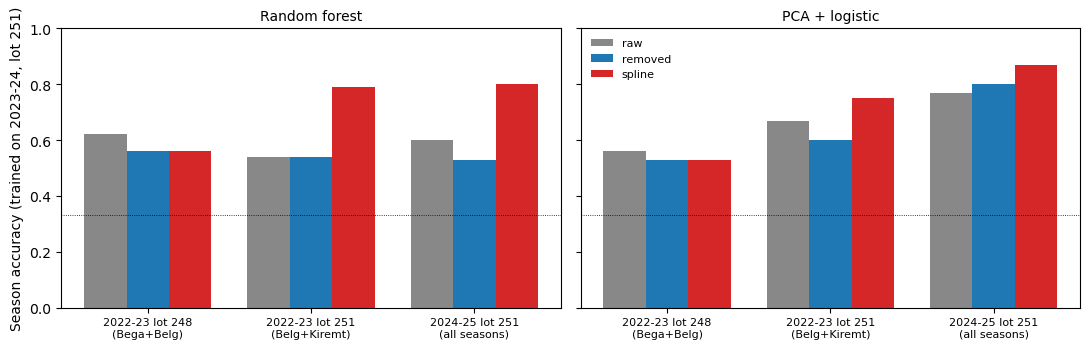

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, model in zip(axes, ('rf', 'linear')):
    sub = lotctl.loc[model]
    x = np.arange(sub.shape[1]); wdt = 0.26
    for k, (rep, col) in enumerate(zip(sub.index, ('#888', '#1f77b4', '#d62728'))):
        ax.bar(x + (k - 1) * wdt, sub.loc[rep].values, wdt, label=rep.replace('_common', ''), color=col)
    ax.set_xticks(x, [t.replace(' (', '\n(') for t in sub.columns], fontsize=8)
    ax.set_title({'rf': 'Random forest', 'linear': 'PCA + logistic'}[model], fontsize=10)
    ax.set_ylim(0, 1); ax.axhline(1/3, color='k', lw=0.6, ls=':')
axes[0].set_ylabel('Season accuracy (trained on 2023-24, lot 251)'); axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

**Read-across.**

* **Within lot 251, corrected still beats raw.**
  * Random forest: 0.79 vs 0.54 on 2022–23 lot-251 filters, and 0.80 vs 0.60 on 2024–25.
  * PCA-logistic: 0.75 vs 0.67, and 0.87 vs 0.77.
  * So baselining does make season easier to recognise, not only by removing the lot background.
* **On lot-248 filters, every representation drops to about 0.53–0.62, and correction does not help.**
  A lot change hurts the season classifier regardless of baseline.
* **The forward-2024 gap is still partly a lot effect.** In that test, raw models are trained on a Bega that is entirely lot 248.
  The 55 → 70 → 78 % numbers should be quoted with that caveat.

A second check: inside 2023 Belg, lot 248 (2 Feb–22 Mar) vs lot 251 (29 Mar–29 May) can be told apart from the spectra alone.
Lot and date are confounded here, so this is indicative only.

In [8]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict
sub = np.where((c == 2023) & (coh.s == 'Belg'))[0]
rows = []
for model in ('rf', 'linear'):
    for rep in ('raw_common', 'spline_common', 'removed_common'):
        X, cols = make_feature_frame(REP[rep][0][sub])
        yp = cross_val_predict(build_model(task='classification', model=model, spectral_columns=cols), X,
                               coh.lot.iloc[sub].values, cv=LeaveOneOut())
        rows.append(dict(model=model, rep=rep, lot_balanced_accuracy=balanced_accuracy_score(coh.lot.iloc[sub], yp)))
pd.DataFrame(rows).round(3)

,model,rep,lot_balanced_accuracy
0,rf,raw_common,0.712
1,rf,spline_common,0.832
2,rf,removed_common,0.655
3,linear,raw_common,1.000
4,linear,spline_common,0.875
5,linear,removed_common,1.000


PCA-logistic separates the two lots perfectly from raw spectra and from the removed component (1.0). It gets 0.875 from corrected spectra.
Most of the lot signature is in the part the spline removes.

## 4. Most of D is FTIR EC, which is itself computed from the spectrum

D = EC_FTIR(X) − BC_HIPS, and r(D, EC_FTIR) = 0.94 in the 2023–24 cycle.
The simplest comparator is a straight line D ≈ a + b·EC_FTIR, fitted on the training years. It uses no spectral channels at all.

A second variant asks whether the spectrum knows anything **beyond** EC: fit the line, then model the residual from the spectrum.

In [9]:
Dv, EC = coh.optical_disagreement_ugm3.values, coh.ec_ftir_ugm3.values
rmse = lambda a, b: float(np.sqrt(np.mean((a - b)**2)))
print('corr(D, EC_FTIR) by cycle:', coh.groupby('cycle_end').apply(lambda g: round(g.optical_disagreement_ugm3.corr(g.ec_ftir_ugm3), 3)).to_dict())
rows, fitted = [], {}
for cyc in (2024, 2025):
    tr, te = c < cyc, c == cyc
    b = np.polyfit(EC[tr], Dv[tr], 1); line_te = np.polyval(b, EC[te]); res_tr = Dv[tr] - np.polyval(b, EC[tr])
    rows.append(dict(cycle=cyc, model='line on EC_FTIR only (no spectrum)', rmse=rmse(Dv[te], line_te)))
    rows.append(dict(cycle=cyc, model='training season mean', rmse=rmse(Dv[te], coh[tr].groupby('s').optical_disagreement_ugm3.mean().reindex(coh.s[te]).values)))
    for rep in ('raw_full', 'spline_common'):
        X, cols = make_feature_frame(REP[rep][0])
        for fam in ('rf', 'linear', 'pls'):
            direct = build_model(task='regression', model=fam, spectral_columns=cols).fit(X[tr], Dv[tr])
            resid = build_model(task='regression', model=fam, spectral_columns=cols).fit(X[tr], res_tr)
            rows.append(dict(cycle=cyc, model=f'{fam} {rep}: D directly', rmse=rmse(Dv[te], direct.predict(X[te]))))
            rows.append(dict(cycle=cyc, model=f'{fam} {rep}: EC line + spectral residual', rmse=rmse(Dv[te], line_te + resid.predict(X[te]))))
ecbase = pd.DataFrame(rows).pivot(index='model', columns='cycle', values='rmse').round(3).sort_values(2024)
ecbase

corr(D, EC_FTIR) by cycle: {2023: 0.95, 2024: 0.943, 2025: 0.879, 2026: 0.447}


cycle,2024,2025
model,,
linear raw_full: EC line + spectral residual,0.401,0.580
linear spline_common: EC line + spectral residual,0.407,0.440
pls raw_full: EC line + spectral residual,0.417,0.528
rf spline_common: EC line + spectral residual,0.427,0.496
pls spline_common: EC line + spectral residual,0.444,0.378
rf raw_full: EC line + spectral residual,0.465,0.611
linear raw_full: D directly,0.487,0.559
line on EC_FTIR only (no spectrum),0.488,0.640
pls spline_common: D directly,0.512,0.475


**Read-across.**

* **In 2023–24, the EC-only line (0.488 µg/m³) ties the best spectral model of D (0.487) and beats every random forest (0.578–0.636).**
  Predicting D directly from the spectrum adds nothing beyond the EC the spectrum already produced.
  The PR's raw-vs-corrected RMSE ranking is a ranking of how well each representation recovers EC_FTIR.
  The PR's component check shows this too: RF predicts EC with R² 0.95 from raw spectra and 0.78 from corrected.
* **There is real spectral information beyond EC.** The EC line plus a spectral residual model reaches 0.40–0.44 in 2023–24 and 0.38–0.50 in 2024–25,
  a 15–40 % RMSE reduction on the line. This is the part of the spectrum worth chasing.
  It is also the part the PR's region importance does not isolate.

## 5. Where the information beyond EC sits: 1800–2250 drops out

The same grouped held-out permutation as the PR (10 repeats, whole named intervals shuffled jointly) is applied to corrected-spectrum models,
for two targets: D directly, and the residual after the EC line.

Raw-spectrum linear and PLS models are left out. Shuffling a raw continuum block pushes them far off the training manifold,
which gives importances of 3–15 µg/m³ that carry no information.

In [10]:
NAMED = {'1560–1700': (1560, 1700), '1700–1800': (1700, 1800), '1800–2250': (1800, 2250), '2250–2400': (2250, 2400),
         '2400–2800': (2400, 2800), '2800–3000': (2800, 3000), '3000–3500': (3000, 3500), '3500–4000': (3500, 4000)}
Xa, w = REP['spline_common']; X, cols = make_feature_frame(Xa)
regs = {k: v for k, v in spectral_regions(w, cols, named_regions=NAMED, bin_width=100., include_whole=False).items() if not k.startswith('bin_')}
rows = []
for cyc in (2024, 2025):
    tr, te = c < cyc, c == cyc
    b = np.polyfit(EC[tr], Dv[tr], 1)
    for target, ytr, yte in (('D directly', Dv[tr], Dv[te]),
                             ('residual after EC line', Dv[tr] - np.polyval(b, EC[tr]), Dv[te] - np.polyval(b, EC[te]))):
        for fam in ('rf', 'linear', 'pls'):
            est = build_model(task='regression', model=fam, spectral_columns=cols).fit(X[tr], ytr)
            g = pd.DataFrame(grouped_region_permutation(est, X[te], yte, regs, task='regression', repeats=10)).groupby('region').importance.mean()
            g.index = [i.split(' ')[0] for i in g.index]
            rows.append(dict(cycle=cyc, target=target, model=fam, **g.to_dict()))
imp = pd.DataFrame(rows).set_index(['cycle', 'target', 'model'])[list(NAMED)].round(3)
imp

1560–1700  1700–1800  1800–2250  2250–2400  2400–2800  2800–3000  3000–3500  3500–4000
cycle target                 model                                                                                         
2024  D directly             rf          0.029      0.011      1.113      0.001      0.001     -0.000      0.015      0.008
                             linear      0.010      0.008      0.000      0.011      0.061      1.921      1.232      0.010
                             pls         0.645      0.205      0.011      0.035      0.135      1.052      0.394      0.006
      residual after EC line rf         -0.000      0.001      0.002      0.001      0.000      0.000      0.004      0.099
                             linear      0.013      0.007     -0.000      0.003      0.099      0.292      0.005      0.130
                             pls         0.446      0.342     -0.001      0.039      0.023      0.352      0.173      0.380
2025  D directly             rf          0.005      0.002      1.180      0.008      0.008      0.001      0.002      0.008
                             linear      1.239      0.496      0.004      0.012      0.003      0.892      0.317      0.016
                             pls         0.738      0.200      0.021      0.030     -0.021      0.524      0.256      0.028
      residual after EC line rf         -0.001      0.005      0.019     -0.001      0.002      0.001      0.006      0.133
                             linear      0.337      0.123      0.001      0.000      0.134      0.344      0.206      0.086
                             pls         0.555      0.332      0.001      0.037      0.227      0.577      0.176      0.227

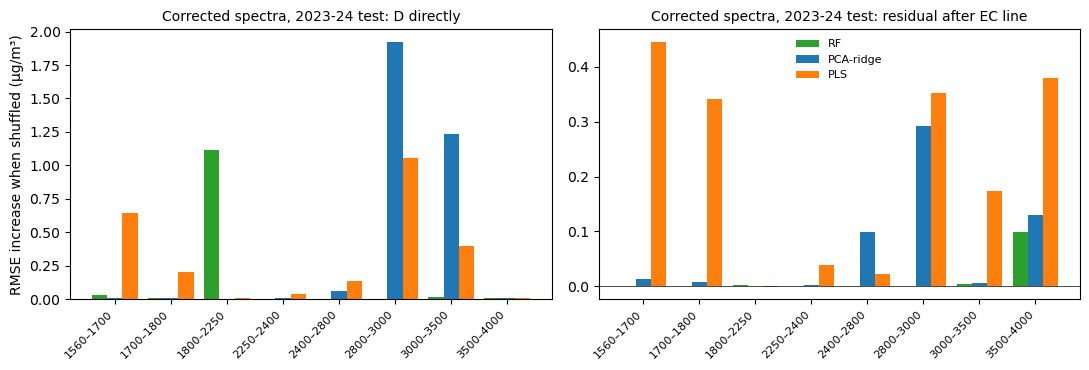

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, target in zip(axes, ('D directly', 'residual after EC line')):
    sub = imp.xs(2024, level='cycle').xs(target, level='target')
    x = np.arange(len(NAMED)); wdt = 0.27
    for k, (fam, col) in enumerate(zip(('rf', 'linear', 'pls'), ('#2ca02c', '#1f77b4', '#ff7f0e'))):
        ax.bar(x + (k - 1) * wdt, sub.loc[fam].values, wdt, label={'rf': 'RF', 'linear': 'PCA-ridge', 'pls': 'PLS'}[fam], color=col)
    ax.set_xticks(x, list(NAMED), rotation=45, ha='right', fontsize=8)
    ax.set_title(f'Corrected spectra, 2023-24 test: {target}', fontsize=10); ax.axhline(0, color='k', lw=0.5)
axes[0].set_ylabel('RMSE increase when shuffled (µg/m³)'); axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

**Read-across.**

* **The 1800–2250 result is random-forest only.** Random forests predicting D lean almost entirely on 1800–2250 (1.11 in 2023–24, 1.18 in 2024–25).
  PCA-ridge and PLS reach equal or better RMSE on the same D with essentially zero weight there (≤ 0.02).
  They rely on 2800–3000 (C–H) and 1560–1700 instead. The forest picks one continuum block as a stand-in for EC magnitude.
* **Once the EC line is removed, 1800–2250 carries nothing in any model or either test year** (≤ 0.02).
  The information beyond EC sits in **3500–4000**, the only interval all three models agree on (0.09–0.38).
  Linear and PLS models also use **2800–3000 C–H** (0.29–0.58) and **1560–1700** (0.34–0.56).
* **The PR's seasonal pattern** (Bega 0.06, Belg 0.52, Kiremt 0.75 at 1800–1900) uses the same RF-on-D target, so it carries the same EC dependence.
  It also follows the spread of D in each season: SD 0.61, 0.83 and 1.36 µg/m³.

In [12]:
pmf = pd.read_csv(T / 'seasonal_pmf_triangulation_20261103/correlations.csv')
display(pmf[(pmf.scope == 'all') & pmf.factor.isin(['factor_2', 'factor_3'])][['factor', 'target_label', 'rho', 'n']].sort_values('rho', key=abs, ascending=False).head(8).round(3))

,factor,target_label,rho,n
9,factor_3,FTIR EC,0.900,231
8,factor_3,FTIR EC minus HIPS BC,0.899,231
7,factor_2,"Mean signed spline-corrected absorbance, 1800–...",0.812,231
4,factor_2,FTIR EC minus HIPS BC,-0.704,231
11,factor_3,"Mean signed spline-corrected absorbance, 1800–...",-0.684,231
10,factor_3,HIPS BC,0.654,231
5,factor_2,FTIR EC,-0.649,231
6,factor_2,HIPS BC,-0.401,231


**PMF.** Factor 3 correlates with FTIR EC at ρ = 0.900, the same strength as its correlation with D (0.899).
It is an FTIR-EC factor, not specifically a disagreement factor.

## Verdict

| PR claim | Status |
|---|---|
| Saved scores, splits, scan grouping, training-only preprocessing, permutation mechanics | **Correct**; reproduced exactly, no leakage found |
| Corrected spectra recognise season better than raw | **Holds** within lot 251. The forward-2024 gap is inflated, because all training Bega filters are lot 248 |
| Raw spectra predict D better in 2023–24, ranking flips in 2024–25 | True for RF and PCA-ridge, not for PLS. Mostly measures recovery of EC_FTIR; a one-variable EC line matches the best model |
| 1800–2250 / 1800–1900 is the strongest lead for baselining | **Not supported.** RF-only, and gone once EC is accounted for. Look at 3500–4000, 2800–3000 and 1560–1700 instead |
| Seasonal differences in 1800–1900 reliance | Same RF-on-D target, so the same EC dependence; scales with each season's spread in D |
| PMF Factor 3 ↔ disagreement | True, but Factor 3 tracks FTIR EC equally (ρ 0.900) |

**What to change before relying on the page:**
1. Add lot (248 / 251 / 253) to the cohort.
2. Report the EC-line comparator next to every D score.
3. Run the region importance on the residual after EC, or on HIPS BC with EC as a covariate, not on D.
4. Move the "1800–2250 priority" wording to the residual-based regions.